# Optimization in PyTorch — Gradient Descent, SGD, Numerical Stability, and L1 Regularization

**General guidelines for this (and future) hometasks**

* **Do not delete the task formulations**
* Many hometasks will be like "implement something, then perform experiments, then write your conclusions". We're sure many of you will delegate the first and the second step to coding agents, but please do at least the final stage yourself :)
* The plots should be meaningful: a plot must have a name, every curve or point cloud on a plot must be labeled
* Plots supporting comparison should actually enable it. For example, if you compare training loss curves of two models, they should be either on the same plot or side by side, with the same axis scales
* It goes without saying that the takeaways should actually follow from the evidence ;)

**Learning goals of this hometask**

By completing this assignment, you will:
1. Understand preprocessing design choices (tokenization provided, fixed vocabulary).
2. Implement and train Logistic Regression manually in PyTorch using SGD.
3. Explain why numerical stability matters in softmax and log-loss.
4. Understand how optimization parameters like learning rate and batch size affect training.
5. Understand the effect of L1 regularization and why it encourages sparsity.
6. Understanding how an optimization algorithm behaves when the loss function has different shapes.


**The dataset and the task**

For this assignment, we will use the SST-2 dataset (  [The Stanford Sentiment Treebank](https://huggingface.co/datasets/stanfordnlp/sst2).), a binary sentiment classification dataset in which each sentence is labeled as either negative or positive.

We will use linear models for classification, which means that we need a fixed number of numerical features to describe each sentence. For that, we'll perform:

* **Preprocessing** - to make the data a little more well-behaved
* **Tokenization** - splitting the sentences into atomic units - in this case, words
* **Feature creation** - turning bags of words into numerical features - word frequencies. We keep only 10,000 most frequent words, because we can only work with fixed-length feature vectors. You'll see that more "serious" models, such as LLMs, use fixed-length vocabularies too, though we'll learn how to do it without discarding information (by using sub-word and bit-wise tokenization).

Tokenization and preprocessing are already implemented for you in this task, but we want you to understand understand the design choices behind the them, so please check the description below (in the hidden cells).

### Loading and preparing the dataset

We will perform minimal text cleaning:

   * convert all text to lowercase

   * keep letters, numbers, spaces, and basic punctuation

   * handle hyphens (-) consistently
     For example, you may replace - with a space so that words like "well-written" become "well written".


In [9]:
!pip install datasets

In [10]:
from datasets import load_dataset
sst2 = load_dataset("SetFit/sst2")

data_train = sst2['train']
data_val = sst2['validation']

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/378 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl:   0%|          | 0.00/1.07M [00:00<?, ?B/s]

dev.jsonl:   0%|          | 0.00/136k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/281k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/6920 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

**Text Cleaning**

Before converting text into a numerical representation (e.g., Bag-of-Words), it is important to apply text cleaning.

The goal of this step is to reduce noise and ensure that similar pieces of text are represented consistently.

We use the following cleaning function:

In [11]:
import re

def clean_text(text:str) -> str:
  #lowercase letters only
  text = text.lower()

  #replace hyphens with space
  text = text.replace('-',' ')

  #keep letters,numbers, spaces, and basic punctuations
  text = re.sub(r'[^a-zA-Z0-9\s.,!?]', '', text)

  #collapse multiple spaces
  text = re.sub(r'\s+', ' ', text).strip()

  return text

#apply cleaning
data_train = data_train.map(lambda x: {'clean_text': clean_text(x['text'])})
data_val = data_val.map(lambda x: {'clean_text': clean_text(x['text'])})



Map:   0%|          | 0/6920 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

In [12]:
from collections import Counter
import random

random.seed(42)

print(f'size of training set: {len(data_train)}')
print(f'size of validation set: {len(data_val)}\n')

for i in range(5):
  r = random.randint(0,len(data_train))
  print(f'{data_train[r]['label_text']} Text: {data_train[r]['clean_text']} ')


train_counts = Counter(data_train["label"])
val_counts = Counter(data_val["label"])

train_total = len(data_train)
val_total = len(data_val)

print("\nTraining set label distribution:")
print(f"Negative (0): {train_counts[0]} ({train_counts[0] / train_total:.2%})")
print(f"Positive (1): {train_counts[1]} ({train_counts[1] / train_total:.2%})")

print("\nValidation set label distribution:")
print(f"Negative (0): {val_counts[0]} ({val_counts[0] / val_total:.2%})")
print(f"Positive (1): {val_counts[1]} ({val_counts[1] / val_total:.2%})")

size of training set: 6920
size of validation set: 872

positive Text: the extent to which it succeeds is impressive . 
positive Text: remarkable for its excellent storytelling , its economical , compressed characterisations and for its profound humanity , it s an adventure story and history lesson all in one . 
positive Text: the unexpected thing is that its dying , in this shower of black and white psychedelia , is quite beautiful . 
negative Text: matrix style massacres erupt throughout ... but the movie has a tougher time balancing its violence with kafka inspired philosophy . 
positive Text: the closest thing to the experience of space travel 

Training set label distribution:
Negative (0): 3310 (47.83%)
Positive (1): 3610 (52.17%)

Validation set label distribution:
Negative (0): 428 (49.08%)
Positive (1): 444 (50.92%)


We convert the text into numerical vectors that can be used as input for machine learning models.

1. Implementing the Bag-of-Words (BoW) representation building a vocabulary using only the training set.

2. Count the frequency of each token across the training corpus.

3. Keep only the top V=10,000 most frequent tokens (or fewer if memory is limited).

4. Convert each sentence into a sparse vector of token counts.

Each vector should represent how many times each vocabulary word appears in the sentence.

For example, if the vocabulary contains: ["movie", "good", "bad"]

Then the sentence: "good movie good"

Should become: [1,2,0]

**Note:** this is a simple bag of word implementation and not standart practice.


In [13]:
def tokenize(text):
  '''Helper function to split the text into words/tokens'''
  return text.split()

def build_vocabulary(data, top_k=10000):
  '''Build a vocabulary from the training data.'''
  token_counter = Counter()
  for text in data['clean_text']:
    tokens = tokenize(text)
    token_counter.update(tokens)
  most_common = token_counter.most_common(top_k)
  vocab = {word: i for i, (word, _) in enumerate(most_common)}
  return vocab

def convert_text_to_vec(text, vocab):
  '''Convert text into a vector of token counts.'''
  tokens = tokenize(text)
  vec = np.zeros(len(vocab), dtype=int)
  for token in tokens:
    if token in vocab:
      vec[vocab[token]] += 1
  return vec

def dataset_to_vec(data,vocab) :
  '''Convert the dataset into a vector of token counts.'''
  vectors = []
  for text in data['clean_text']:
    vec = convert_text_to_vec(text, vocab)
    vectors.append(vec)
  return np.array(vectors)


In [14]:
import numpy as np

# Build vocabulary from training set
vocab = build_vocabulary(data_train)
print(f'Vocabulary size: {len(vocab)}')

# Vectorize training data
train_vectors = dataset_to_vec(data_train, vocab)
print(f'Vectorized training data shape: {train_vectors.shape}')

# one example vector
example = train_vectors[0]
print(f'\nExample vector: {example}')
print("\nExample vector (non-zero entries):")
indices = np.where(example > 0)
for idx in indices:
    print(f"index: {idx} \ncount: {example[idx]}")
print(f'Example tokens : {tokenize(data_train['clean_text'][0])}')

print(f'Length of tokens: {len(tokenize(data_train['clean_text'][0]))}')
print(f'Length of non-zero entries: {len(indices[0])}')

Vocabulary size: 10000
Vectorized training data shape: (6920, 10000)

Example vector: [0 1 1 ... 0 0 0]

Example vector (non-zero entries):
index: [   1    2    3    4    5   66  118  119  361  554  646 1317 1822 4926
 7197 7198] 
count: [1 1 1 3 1 1 1 1 1 1 1 1 1 1 1 1]
Example tokens : ['a', 'stirring', ',', 'funny', 'and', 'finally', 'transporting', 're', 'imagining', 'of', 'beauty', 'and', 'the', 'beast', 'and', '1930s', 'horror', 'films']
Length of tokens: 18
Length of non-zero entries: 16


**Our training data for the task 1 will be:**

In [15]:
X_train = train_vectors
y_train = np.array(data_train["label"], dtype=np.float32)
X_val = dataset_to_vec(data_val, vocab)
y_val =  np.array(data_val["label"], dtype=np.float32)


### **Part 1 - Implement SGD for Logistic Regression in PyTorch (70 points)**

#### **Task 1.1 - Binary vs. Softmax Formulation and Numerical Stability of Cross-Entropy Loss (10 points)**



In this task, you will explore two ways to formulate the loss function for a classification problem and understand why numerical stability is important.

**a. Binary formulation**

   In the binary formulation, the model has:

   * a single output
   * sigmoid activation
   * binary cross-entropy loss

   This produces a probability: P(y=1|x)
   
   A prediction is then obtained using a threshold:
   * predict class 1 if p>0.5
   * otherwise predict class 0

   For binary logistic regression, the standard loss function is the **binary cross-entropy loss**:

   $L= -\frac{1}{N}\sum_{i=1}^N[y_ilog(\hat{y_i})+(1-y_i)log(1-\hat{y_i})]$

   where $\hat{y_i}$ is the predicted probability after applying sigmoid.

   Since this loss contains both: $log(\hat{y})$ and $log(1-\hat{y})$ , numerical problems may appear if $\hat{y_i}$ becomes extremely close to 0 or 1.

   A stable implementation should therefore clamp the predicted probabilities:
```
y_pred = # SIGMOID(LOGITS)
epsilon = 1e-15  
y_pred = torch.clamp(y_pred, epsilon, 1 - epsilon)
log_loss = # <SMTH FROM y_pred>
```

**Note:** the threshold 0.5 is used only to convert probabilities into class predictions for evaluation.
It must not be used inside the loss function.

**b. Softmax formulation**

  Now, we will reformulate the same problem as a 2-class classification problem using softmax (This formulation is more general and can also be used for more than 2 classes.).
  
  **Step 1 — Convert labels to one-hot encoding**
  
  In our dataset the labels are either 1 or 0 (i.e positive or negetive). To use softmax will require us to convert the labels into a one-hot representation:
  * class 0 ---> [1,0]
  * class 1 ---> [0,1]

  Now our model will output 2 outputs instead of 1 and we will require to apply softmax to get the probability of class 0 vs. class 1.

  **Step 2 - Implementing softmax and log-loss**
  
   This can be implemented in two ways:

  1. **Naive version:**
  
     Given logits z = [$z_1,z_2,...,z_k$]

     softmax($z_i$) = $\frac{\exp(z_i)}{\sum_j\exp(z_j)}$


  2. **Stable version:**

     softmax($z_i$) = $\frac{\exp(z_i-max(z))}{\sum_j\exp(z_j-max(z))}$

   Than the cross entropy loss for the true class y is :

   **L = -log(softmax($z_y$))**

   or equivalently, for one-hot labels:
   
   **$L= -\sum_{c=1}^Ky_clog(\hat{y_c})$**

**Task**

A. Conceptual questions

For both the binary and softmax formulations, explain:

* Why do we need numerical stability? Where can the naive implementation fail?

-> If the logits have big values at some point in the training, the exponents will explode and likely result in an overflow or NaNs

* Why does the stability transformation not change the final softmax probabilities?

-> Both numerator and denominator are multiplied by ${\exp(-max(z))}$

$\frac{\exp(z_i-max(z))}{\sum_j\exp(z_j-max(z))}=\frac{\exp(-max(z))\exp(z_i)}{exp(-max(z))\sum_j\exp(z_j)}=\frac{\exp(z_i)}{\sum_j\exp(z_j)}$

* Why does this transformation improve numerical stability?

-> By subtracting by max(z), we make sure that all the values inside the exponent will be negative or zero, therefore, the exponent will be between 0 and 1, and numerically stable

B. Implementation
1. Implement a binary cross-entropy loss function for the binary formulation.
2. Make sure your implementation is numerically stable.




In [16]:
import torch

def binary_cross_entropy_loss(y_pred, y_true):
    """
    Compute the binary cross-entropy loss for a logistic regression model.
    """
    epsilon = 1e-15
    # clamp y_pred for numerical stability
    y_pred = torch.clamp(y_pred, epsilon, 1 - epsilon)
    # Compute binary log-loss remmber that the loss should provide a scalar value for the backwards to work
    return -torch.mean(y_true * torch.log(y_pred) + (1 - y_true) * torch.log(1 - y_pred))

####**Task 1.2. - Implement Logistic Regression in PyTorch (10 points)**



In this task, you will implement a logistic regression model from scratch using PyTorch primitives.

The logistic regression prediction function is:

$\hat{Y} = \frac{1}{1+exp^{-(wx +b)}}$

Complete the class below.

You are required to implement:

1. weight initialization (with different options)
2. the forward pass (logits + sigmoid)
3. prediction logic (thresholding)

In [17]:
import torch
import torch.nn as nn

class LogisticRegression(nn.Module):

    def __init__(self, n_features, init="zeros"):
        """
        Parameters
        ----------
        n_features : int
            Number of input features

        init : str or torch.Tensor
            Initialization method for weights:
            - "zeros"  -> initialize weights to zeros
            - "random" -> small random values (recommended scale ~0.01)
            - torch.Tensor -> use provided tensor
        """

        super().__init__()

        # TODO:
        # Initialize the weight vector `w` based on the `init` argument
        # Make sure:
        # - shape is (n_features, 1)
        # - random initialization uses SMALL values (important!)
        # - if init is a tensor, clone + detach it

        if init == "zeros":
            w = torch.zeros(n_features, 1)

        elif init == "random":
            scale = 1e-2
            w = torch.rand(n_features, 1) * scale

        elif isinstance(init, torch.Tensor):
            w = init.clone().detach()

        else:
            raise ValueError("init must be 'zeros', 'random', or a torch.Tensor")

        # TODO:
        # Wrap weights and bias using nn.Parameter
        self.w = nn.Parameter(w)
        self.b = nn.Parameter(torch.tensor(0.0))

    def forward(self, x):
        """
        Forward pass

        Steps:
        1. Compute logits: x @ w + b
        2. Apply sigmoid to get probabilities

        Returns
        -------
        probs : torch.Tensor
            Values in range [0, 1]
        """

        # TODO:
        logits = x @ self.w + self.b
        probs = 1 / (1 + torch.exp(-logits))

        return probs

    def predict(self, x):
        """
        Convert probabilities to class predictions

        Rule:
        - class 1 if p >= 0.5
        - class 0 otherwise
        """

        # TODO:
        probs = self.forward(x)
        preds = probs >= 0.5

        return preds

In [18]:
reg = LogisticRegression(3, init="random")
reg.predict(torch.tensor([1,2,3], dtype=torch.float32))

tensor([True])

####**Task 1.3 - Train Logistic Regression with SGD Using Your Previous Implementations (10 point)**



In this task, you will train the logistic regression model you implemented earlier using mini-batch stochastic gradient descent (SGD).

You must use:

1. your LogisticRegression class from Task 1.2
2. your binary_cross_entropy_loss function from Task 1.1

The goal of this task is to practice building a full training loop in PyTorch while keeping the model and loss implementations modular.

Your function should
1. Initialize a LogisticRegression model
2. Train it on the training set using mini-batch SGD
3. Record the training log-loss after each epoch
4. Compute and report evaluation metrics on both the training and validation sets after each epoch.
You may choose any evaluation metric you find appropriate, such as accuracy, precision, recall, or F1-score, but you must briefly explain why this metric is suitable for this task.
5. Save the model parameters w and b after each batch update into a history log
6. Return:
   * the final trained parameters w and b
   * the batch-wise history of w and b


Bellow is a suggested skeleton you may revised



In [19]:
import torch
from sklearn.metrics import accuracy_score, f1_score

def sgd_logistic_regression(
    X_train, y_train,
    X_val, y_val,
    lr=0.01,
    epochs=20,
    batch_size=100,
    init="zeros",
    penalty='none',          # For Task 1.5 : options: 'none', 'l1', 'l2'
    reg_lambda=0.0,          # For Task 1.5
    metric='accuracy',
    print_metrics=False
):
    """
    Train a logistic regression model using mini-batch SGD.

    You must use:
    - LogisticRegression
    - binary_cross_entropy_loss

    Parameters
    ----------
    X_train, y_train : training data
    X_val, y_val     : validation data
    lr : float
        Learning rate
    epochs : int
        Number of passes over the training data
    batch_size : int
        Mini-batch size
    init : str
        Weight initialization passed to LogisticRegression
    penalty : str
        'none', 'l1', or 'l2'
    reg_lambda : float
        Regularization strength
    metric : str
        Evaluation metric to report ('accuracy' , 'f1' or other)
    print_metrics : bool
        Whether to print metrics after each epoch

    Returns
    -------
    w : numpy.ndarray
        Final learned weights
    b : numpy.ndarray
        Final learned bias
    history : list
        Batch-wise history of parameter values
    epoch_log : list
        Per-epoch logs (loss + metrics)
    """


    # 1. Convert data to tensors

    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

    n_samples, n_features = X_train_tensor.shape


    # 2. Initialize model

    model = LogisticRegression(n_features=n_features, init=init)


    # 3. Create optimizer

    optimizer = torch.optim.SGD(model.parameters(), lr=lr)


    # 4. Create logs

    history = []      # save w, b after each batch update
    epoch_log = []    # save epoch-level loss and metrics


    # 5. Training loop

    for epoch in range(epochs):

        # TODO:
        # Shuffle the training data at the beginning of each epoch
        perm = torch.randperm(n_samples)
        X_train_epoch = X_train_tensor[perm]
        y_train_epoch = y_train_tensor[perm]

        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            # TODO:
            # Select mini-batch
            X_batch = X_train_epoch[start:end]
            y_batch = y_train_epoch[start:end]

            # TODO:
            # Forward pass
            y_pred = model(X_batch)

            # TODO:
            # Compute non-regularized BCE loss using your function
            data_loss = binary_cross_entropy_loss(y_pred, y_batch)

            # TODO in task 1.5:
            # Add regularization if needed
            # penalty == 'l1'  -> reg_lambda * ||w||_1
            # penalty == 'l2'  -> reg_lambda * ||w||_2^2
            # penalty == 'none' -> no regularization
            if penalty == 'l1':
               reg_term = reg_lambda * torch.norm(model.w, p=1)
            elif penalty == 'l2':
               reg_term = reg_lambda * torch.norm(model.w, p=2)**2
            else:
               reg_term = torch.tensor(0.0)

            loss = data_loss + reg_term

            # TODO:
            # Backward pass and optimization step
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # TODO:
            # Save current parameter values after the batch update
            history.append({
                'epoch': epoch,
                'batch_start': start,
                'w': model.w.detach().clone(),
                'b': model.b.detach().clone()
            })


        # 6. Epoch-level evaluation
        with torch.no_grad():

            # TODO:
            # Compute probabilities on full train/val sets
            y_pred_train = model(X_train_tensor)
            y_pred_val = model(X_val_tensor)

            # TODO:
            # Compute NON-regularized train loss and val loss
            train_loss = binary_cross_entropy_loss(y_pred_train, y_train_tensor)
            val_loss = binary_cross_entropy_loss(y_pred_val, y_val_tensor)

            # TODO:
            # Convert probabilities to binary predictions
            y_hat_train = y_pred_train >= 0.5
            y_hat_val = y_pred_val >= 0.5

            # TODO:
            # Compute evaluation metric
            y_hat_train_np = y_hat_train.cpu().numpy()
            y_hat_val_np   = y_hat_val.cpu().numpy()

            if metric == 'f1':
                train_metric = f1_score(y_train, y_hat_train_np)
                val_metric   = f1_score(y_val, y_hat_val_np)
            else:
                # Accuracy
                train_metric = accuracy_score(y_train, y_hat_train_np)
                val_metric   = accuracy_score(y_val, y_hat_val_np)

        epoch_log.append({
            'epoch': epoch,
            'train_loss': train_loss.item(),
            'val_loss': val_loss.item(),
            'train_metric': train_metric,
            'val_metric': val_metric
        })

        if print_metrics:
            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Train Loss: {train_loss.item():.4f} | "
                f"Val Loss: {val_loss.item():.4f} | "
                f"Train {metric}: {train_metric:.4f} | "
                f"Val {metric}: {val_metric:.4f}"
            )

    return model.w.detach().numpy(), model.b.detach().numpy(), history, epoch_log

In [20]:
w, b, history, epoch_log = sgd_logistic_regression(
    X_train, y_train,
    X_val, y_val, print_metrics=True)

Epoch 1/20 | Train Loss: 0.6877 | Val Loss: 0.6875 | Train accuracy: 0.5332 | Val accuracy: 0.5206
Epoch 2/20 | Train Loss: 0.6842 | Val Loss: 0.6837 | Train accuracy: 0.5535 | Val accuracy: 0.5459
Epoch 3/20 | Train Loss: 0.6812 | Val Loss: 0.6804 | Train accuracy: 0.5760 | Val accuracy: 0.5894
Epoch 4/20 | Train Loss: 0.6785 | Val Loss: 0.6775 | Train accuracy: 0.5860 | Val accuracy: 0.6055
Epoch 5/20 | Train Loss: 0.6760 | Val Loss: 0.6747 | Train accuracy: 0.6088 | Val accuracy: 0.6273
Epoch 6/20 | Train Loss: 0.6737 | Val Loss: 0.6722 | Train accuracy: 0.6134 | Val accuracy: 0.6502
Epoch 7/20 | Train Loss: 0.6715 | Val Loss: 0.6697 | Train accuracy: 0.6163 | Val accuracy: 0.6583
Epoch 8/20 | Train Loss: 0.6695 | Val Loss: 0.6675 | Train accuracy: 0.6191 | Val accuracy: 0.6583
Epoch 9/20 | Train Loss: 0.6675 | Val Loss: 0.6654 | Train accuracy: 0.6231 | Val accuracy: 0.6594
Epoch 10/20 | Train Loss: 0.6656 | Val Loss: 0.6633 | Train accuracy: 0.6263 | Val accuracy: 0.6606
Epoch 11/

####**Task 1.4 - Experiments (20 points)**




Run multiple experiments with different combinations of:
* learning rates - [0.01, 0.03, 0.1 , 0.3 , 1.0]
* batch sizes - [50, 100 , 200]

For each experiment, record the final train and validation evaluation metric and the log-loss.

**Visualization:**

Present your results using a heatmap, where:
* X-axis: learning rate
* Y-axis: batch size
* Values: evaluation metric (train / validation)


**Analysis:**

Explain (in text) how learning rate and batch size affect:
- convergence speed
- stability of training
- final performance

Support your explanation using the patterns observed in your heatmap.


In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


def sweep_sgd_logistic_regression(
    X_train, y_train,
    X_val, y_val,
    sweep_params,
    fixed_params=None,
    metric='accuracy',
    plot=True,
    log_x=False
):
    """
    Sweep over any 1 or 2 hyperparameters of sgd_logistic_regression.

    Parameters
    ----------
    X_train, y_train, X_val, y_val : array-like
        Training and validation data.
    sweep_params : dict
        Keys are parameter names of sgd_logistic_regression,
        values are lists of values to sweep over.
        Supports 1 or 2 parameters (2 produces a heatmap).
        Example: {'lr': [0.01, 0.1], 'batch_size': [50, 100]}
    fixed_params : dict or None
        Any additional fixed kwargs passed to sgd_logistic_regression.
        Example: {'epochs': 30, 'init': 'random'}
    metric : str
        'accuracy' or 'f1'
    plot : bool
        Whether to display plots after the sweep.

    Returns
    -------
    df : pd.DataFrame
        Results with columns for each swept param + train/val metric/loss.
    """
    if fixed_params is None:
        fixed_params = {}

    param_names = list(sweep_params.keys())
    param_values = list(sweep_params.values())

    if len(param_names) < 1 or len(param_names) > 2:
        raise ValueError("sweep_params must contain 1 or 2 parameters")

    # Build all combinations
    if len(param_names) == 1:
        combos = [{param_names[0]: v} for v in param_values[0]]
    else:
        combos = [
            {param_names[0]: v0, param_names[1]: v1}
            for v0 in param_values[0]
            for v1 in param_values[1]
        ]

    results = []
    for i, combo in enumerate(combos, 1):
        print(f"Running experiment {i}/{len(combos)} | {combo}")

        run_kwargs = {**fixed_params, **combo, 'metric': metric}
        w, b, history, epoch_log = sgd_logistic_regression(
            X_train, y_train,
            X_val, y_val,
            **run_kwargs
        )

        final = epoch_log[-1]
        row = {
            **combo,
            'train_metric': final['train_metric'],
            'val_metric': final['val_metric'],
            'train_loss': final['train_loss'],
            'val_loss': final['val_loss'],
            'weights': w
        }
        results.append(row)

    df = pd.DataFrame(results)

    if plot:
        _plot_sweep(df, param_names, metric, log_x=log_x)

    return df


def _plot_sweep(df, param_names, metric, log_x=False):
    """Plot sweep results: line plot for 1 param, heatmap for 2."""

    if len(param_names) == 1:
        p = param_names[0]
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        axes[0].plot(df[p], df['train_metric'], 'o-', label='Train')
        axes[0].plot(df[p], df['val_metric'], 's--', label='Val')
        axes[0].set_xlabel(p)
        axes[0].set_ylabel(metric)
        axes[0].set_title(f'{metric} vs {p}')
        axes[0].legend()

        axes[1].plot(df[p], df['train_loss'], 'o-', label='Train')
        axes[1].plot(df[p], df['val_loss'], 's--', label='Val')
        axes[1].set_xlabel(p)
        axes[1].set_ylabel('Loss')
        axes[1].set_title(f'Loss vs {p}')
        axes[1].legend()

        if log_x:
          axes[0].set_xscale('log')
          axes[1].set_xscale('log')


        plt.tight_layout()
        plt.show()

    else:
        p0, p1 = param_names
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        heatmap_train = df.pivot(index=p0, columns=p1, values='train_metric')
        heatmap_val = df.pivot(index=p0, columns=p1, values='val_metric')

        sns.heatmap(heatmap_train, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[0])
        axes[0].set_title(f"Train {metric}")

        sns.heatmap(heatmap_val, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[1])
        axes[1].set_title(f"Validation {metric}")

        plt.tight_layout()
        plt.show()

Running experiment 1/15 | {'batch_size': 50, 'lr': 0.01}
Running experiment 2/15 | {'batch_size': 50, 'lr': 0.03}
Running experiment 3/15 | {'batch_size': 50, 'lr': 0.1}
Running experiment 4/15 | {'batch_size': 50, 'lr': 0.3}
Running experiment 5/15 | {'batch_size': 50, 'lr': 1.0}
Running experiment 6/15 | {'batch_size': 100, 'lr': 0.01}
Running experiment 7/15 | {'batch_size': 100, 'lr': 0.03}
Running experiment 8/15 | {'batch_size': 100, 'lr': 0.1}
Running experiment 9/15 | {'batch_size': 100, 'lr': 0.3}
Running experiment 10/15 | {'batch_size': 100, 'lr': 1.0}
Running experiment 11/15 | {'batch_size': 200, 'lr': 0.01}
Running experiment 12/15 | {'batch_size': 200, 'lr': 0.03}
Running experiment 13/15 | {'batch_size': 200, 'lr': 0.1}
Running experiment 14/15 | {'batch_size': 200, 'lr': 0.3}
Running experiment 15/15 | {'batch_size': 200, 'lr': 1.0}


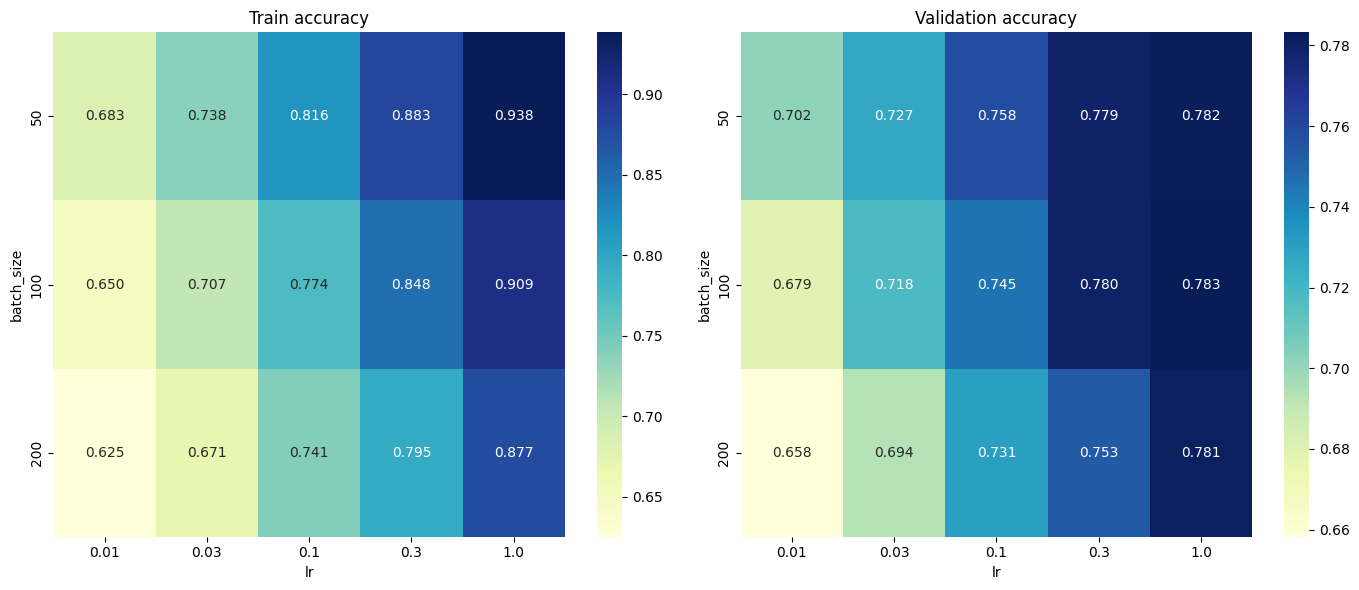

In [22]:
df = sweep_sgd_logistic_regression(
    X_train, y_train, X_val, y_val,
    sweep_params={
        'batch_size': [50, 100, 200],
        'lr': [0.01, 0.03, 0.1, 0.3, 1.0],
    },
    fixed_params={'epochs': 20},
    metric='accuracy'
)

**Analysis:**


As we can see in the heatmaps above, a higher learning rate increase convergence speed, but might make the training less stable and hurt performance.
A smaller batch size makes convergence faster (more backprops overall) but can hurt stability and final performance too.

####**Task 1.5 — L1 Regularization and Sparsity (20 points)**



In this task, you will extend your implementation from Task 1.2 (SGD training) to include **L1 regularization**, and study how it affects the model.

**What is Regularization/ Penalty**

When there are too many features, some features might not be so important at all, but if we keep it, and try to fit our model to it perfectly, then it might overfit, trying to capture noisy (irrelevant) data or patterns. To reduce this overfitting so the model generalizes well and remove noisy data we use **regularization**. In linear models, mostly these regularization techniques are used:

* **L1 Penalty**: adding $\lambda *\sum{|w_i|}$ to the loss function

* **L2 Penalty**: adding $\lambda *\sum{||w||_i^2}$ to the loss function


**Why is this important?**

L1 *sparsifies* data, with part of weights being pushed strongly towards zero (with the right optimization technique, these weights become almost zero).
This leads to implicit feature selection.

In contrast, L2 shrinks weights but rarely makes them exactly zero.

**Task**

1. Modify your `sgd_logistic_regression` function from Task 1 to include L1 penalty.

2. Compare weight initialization:
   
   Try initializing the weight vector w in two different ways:
   * All zeros
   * Small random values
   
   Compare:
    * Stability (does training diverge? NaNs?)
    * Final performance
    * Sparsity (how many weights go to zero, use a small tolerance like 1e-7). Note that you'll unlikely get zeros. You'd need special optimization methods such as *proximal descent* to get true feature elimination; with SGD you'll still make part of the weights really small, so you'll still observe the pattern.
   
3. Study the effect of $\lambda$
   
   Run experiments with:

          reg_lambda = [0,1e-4,1e-3,1e-2,1e-1]
    
     Keep other parameters fixed (recommended):
     
      *  lr = 0.1
      *  batch_size = 100
     
     For each λ, record:
      * Train metric (for example accuracy or F1)
      * Validation metric
      * Number of non-zero weights that exceed a small threshold such as 1e-7

4. Visualization
     
     Plot:
       
     * number of non-zero weights vs lambda
     * train metric vs lambda
     * for a subset of features that get eliminated by the l1 regularization, training dynamics of their weights (weight vs step)

5. Write a small paragraph summarizing your insights

Running experiment 1/2 | {'init': 'zeros'}
Running experiment 2/2 | {'init': 'random'}


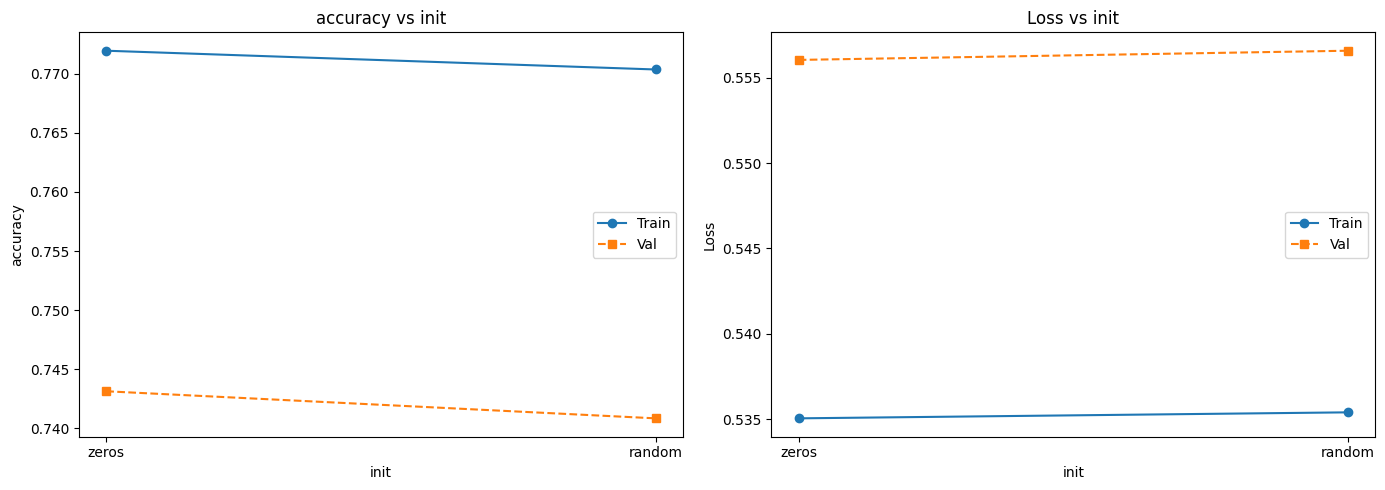

In [36]:
df = sweep_sgd_logistic_regression(
    X_train, y_train, X_val, y_val,
    sweep_params={'init': ['zeros', 'random']},
    fixed_params={'epochs': 20, 'lr': 0.1, 'batch_size': 100},
    metric='accuracy'
)


Running experiment 1/5 | {'reg_lambda': 0}
Running experiment 2/5 | {'reg_lambda': 0.0001}
Running experiment 3/5 | {'reg_lambda': 0.001}
Running experiment 4/5 | {'reg_lambda': 0.01}
Running experiment 5/5 | {'reg_lambda': 0.1}


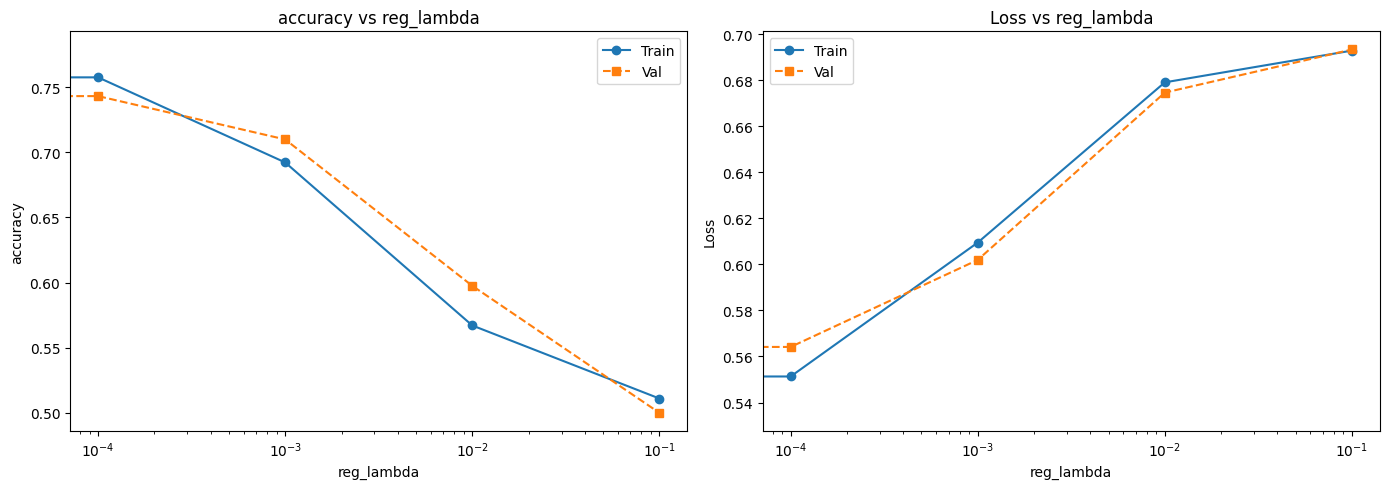

In [39]:
df = sweep_sgd_logistic_regression(
    X_train, y_train, X_val, y_val,
    sweep_params={'reg_lambda': [0,1e-4,1e-3,1e-2,1e-1]},
    fixed_params={'penalty': 'l1', 'epochs': 20, 'lr': 0.1, 'batch_size': 100},
    metric='accuracy', log_x=True
)


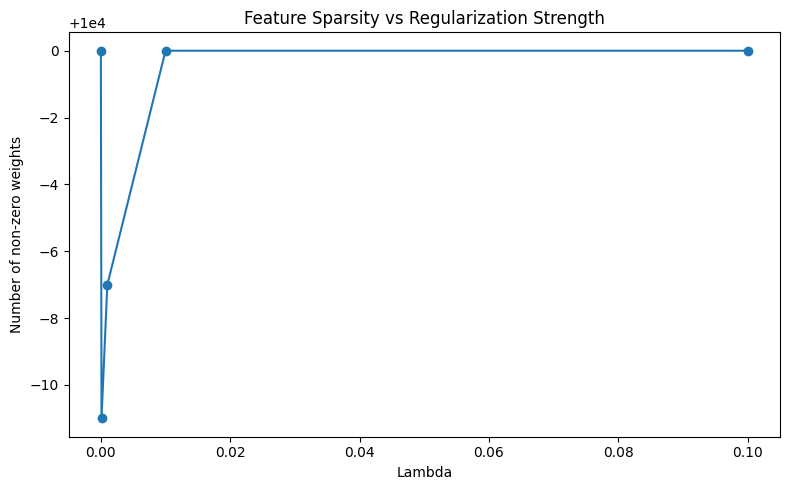

In [40]:

df['n_nonzero'] = df['weights'].apply(lambda w: np.sum(np.abs(w) > 1e-7))

plt.figure(figsize=(8, 5))
plt.plot(df['reg_lambda'], df['n_nonzero'], 'o-')
plt.xlabel('Lambda')
plt.ylabel('Number of non-zero weights')
plt.title('Feature Sparsity vs Regularization Strength')
plt.tight_layout()
plt.show()

#### Conclusions

Initialization (zeros vs. random): Both initialization strategies converged to the same final accuracy and loss, which is expected for logistic regression since its convex loss surface guarantees a unique global minimum regardless of starting point.

Regularization sweep (L1, λ ∈ {0, 1e-4, 1e-3, 1e-2, 1e-1}): Increasing λ monotonically degraded both training and validation accuracy while raising loss. This indicates the dataset does not suffer from overfitting — the model generalizes well even without regularization, so penalizing weight magnitude only hurts performance without providing any benefit.

Feature sparsity: Despite using L1 regularization, the number of near-zero weights remained largely unchanged across all λ values. This is partly a limitation of SGD-based optimization, which approximates sparsity rather than producing exact zeros as coordinate descent methods do. The flat sparsity curve further supports the conclusion that the chosen λ values were not strong enough to meaningfully compress the weight vector, or that the weights were already small due to the simplicity of the problem.
To check that there was no error, we tried with lambda = 100 and we observe strong feature sparsity (all weights are zero) which shows that it functions as intended.

Overall: For this dataset, regularization is not necessary. The model trained with λ=0 achieves the best trade-off between accuracy and loss, and both initialization strategies are equally valid starting points.



### **Part 2 - Comparing Optimization Algorithms on a Simple vs. Difficult Function (30 points)**


In this task, you will implement and compare several optimization algorithms on two different mathematical functions.

An optimization algorithm is a method used to update the model's parameters (weights and bias) in order to minimize the loss function.

At each step, it uses the gradients (how the loss changes) to decide:
- in which direction to move
- and how big the update should be

Different optimizers (like SGD, Adam) differ in how they use the gradients and how they control the step size, which affects how fast and how stably the model learns.

The purpose of this task is to help you build intuition for how optimization behaves in:

1. a simple convex function

2. a function with a narrow curved valley

You will implement the following optimizers:

* Gradient Descent (GD)
* Momentum
* AdaGrad
* Adam

Use your optimizers on the following functions:

Function A — Convex bowl:

$f(x,y)= x^2 +4y^2$

This is a simple convex function with a single global minimum.

Function B — the Six-hump Camel function:

$$
\left(4-2.1x^2+\frac{x^4}{3}\right)x^2+xy+\left(-4+4y^2\right)y^2.
$$

This function is much harder to optimize. It has two global minima: $(0.0898, -0.7126)$ and $(-0.0898,0.7126)$, with value about $-1.0316$ - and also several local minina.

Start from at least one non-optimal initial point, for example: (-2, -1.5)


**Task**

For each optimizer and for each function:

1. Initialize the parameters (x,y)
2. repeatedly compute the gradient
3. Update the parameters according to the optimizer rule
4. Record:
  * the function value at each iteration
  * the parameter values $(x_t,y_t)$ at each iteration

**Goal**

Compare how the different optimizers behave on:

* a simple convex function
* a difficult non-convex function

In particular, observe:

* how quickly each optimizer converges
* whether the optimization path is smooth or oscillatory
* whether an optimizer that works well on the convex bowl also works well on Camel
* how the geometry of the function affects the optimization process

**Coding**

Fill in the gaps in the implementation of the optimization method. By the way, you might find this code very repetitive. Can you find a way of shrinking it and getting rid of repetitions?

**Visualization**

Create the following plots:
1. Function value vs. iteration number
2. Optimization trajectories in the (x,y) plane. Use the `plot_trajectories_camel_log` function or create your own function to make an animation/gif.

For each question, please plot the behaviour of all optimization methods on one plot so that you could compare them.

**Analysis**

Summarize your findings in 2-3 text paragraphs. Things to ponder:

* Which optimizer performs best on the convex bowl?
* Which optimizer performs best on the Camel function? Will any of them reliably find global optima or will all of them get trapped in local minina from time to time, depending on the starting point.
* Do the same hyperparameters work equally well for both functions?
* What advantages do Momentum, AdaGrad, and Adam provide compared to plain Gradient Descent?

In [27]:
import torch
import matplotlib.pyplot as plt

# Convex bowl
def bowl(theta):
    x, y = theta[0], theta[1]
    return x**2 + 2*y**2


# camel
def camel(theta):
    x, y = theta[0], theta[1]
    return (4 - 2.1 * x**2+ x**4 / 3) * x**2 + x * y + (-4 + 4 * y**2) * y**2


def plot_trajectories_camel_log(f, results, xlim=(-3, 3), ylim=(-2, 2), title="Optimization Trajectories"):
    x_values = np.linspace(xlim[0], xlim[1], 400)
    y_values = np.linspace(ylim[0], ylim[1], 400)
    X, Y = np.meshgrid(x_values, y_values)

    grid = np.stack((X, Y), axis=-1)
    Z = f(torch.tensor(grid, dtype=torch.float32)).detach().numpy()

    plt.figure(figsize=(8, 6))
    plt.contour(X, Y, np.log1p(Z), levels=30)

    for name, (trajectory, _) in results.items():
        plt.plot(trajectory[:, 0], trajectory[:, 1], marker='o', markersize=2, label=name)

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [28]:
def gradient_descent(f, theta0, lr=0.001, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(n_steps):
        # TODO: compute loss
        loss = f(theta)

        # TODO: compute gradients
        loss.backward()

        # TODO: update parameters
        with torch.no_grad():
          theta -= lr * theta.grad

        # reset gradients
        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

def momentum(f, theta0, lr=0.001, beta=0.9, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
    v = torch.zeros_like(theta)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(n_steps):
        loss = f(theta)
        loss.backward()

        with torch.no_grad():
            # TODO: update velocity
            v = beta * v + theta.grad
            # TODO: update parameters
            theta -= lr * v

        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

def adagrad(f, theta0, lr=0.1, eps=1e-8, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
    G = torch.zeros_like(theta)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(n_steps):
        loss = f(theta)
        loss.backward()

        with torch.no_grad():
            # TODO: accumulate squared gradients
            G += theta.grad ** 2
            # TODO: update parameters
            theta -= (lr / (torch.sqrt(G) + eps)) * theta.grad

        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

def adam(f, theta0, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
    m = torch.zeros_like(theta)
    v = torch.zeros_like(theta)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(1, n_steps + 1):
        loss = f(theta)
        loss.backward()

        with torch.no_grad():
            # TODO: update moments
            m = beta1 * m + (1 - beta1) * theta.grad
            v = beta2 * v + (1 - beta2) * (theta.grad ** 2)

            # TODO: bias correction
            m_hat = m / (1 - beta1 ** step)
            v_hat = v / (1 - beta2 ** step)

            # TODO: update parameters
            theta -= lr * m_hat / (torch.sqrt(v_hat) + eps)

        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

#Run experiments

theta0 = torch.tensor([-1.5, 1.5])

lr=0.1
beta=0.9

results_bowl = {
    "GD": gradient_descent(bowl, theta0, lr=lr),
    "Momentum": momentum(bowl, theta0, lr=lr, beta=beta),
    "AdaGrad": adagrad(bowl, theta0, lr=lr),
    "Adam": adam(bowl, theta0, lr=lr)
}

lr=0.01

results_camel = {
    "GD": gradient_descent(camel, theta0, lr=lr),
    "Momentum": momentum(camel, theta0, lr=lr, beta=beta),
    "AdaGrad": adagrad(camel, theta0, lr=lr),
    "Adam": adam(camel, theta0, lr=lr)
}

/tmp/ipykernel_1770/1707118723.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
/tmp/ipykernel_1770/1707118723.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
/tmp/ipykernel_1770/1707118723.py:51: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
/tmp/ipykernel_1770/1707118723.py:75: UserWarning: To copy construct from a tensor,

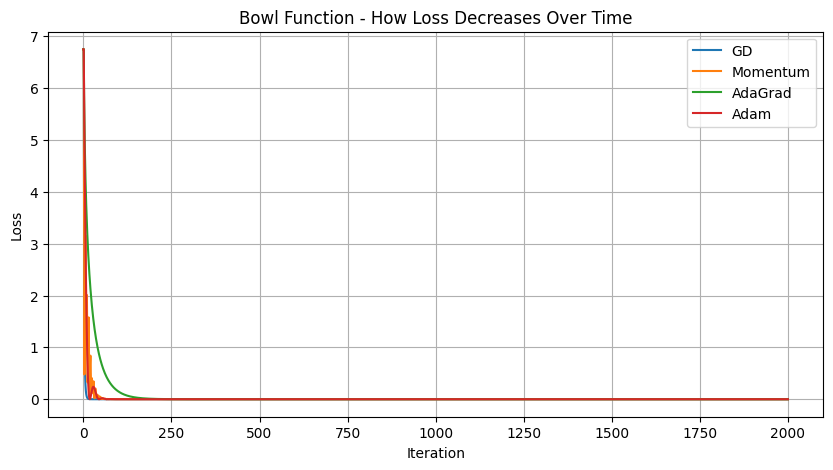

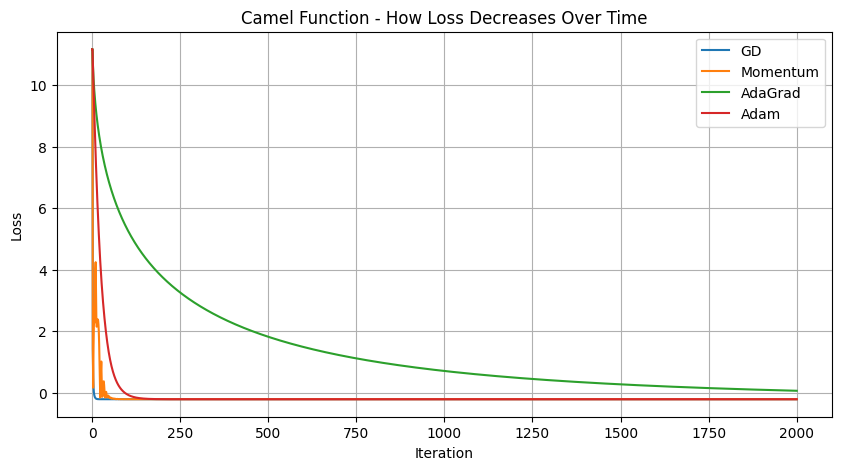

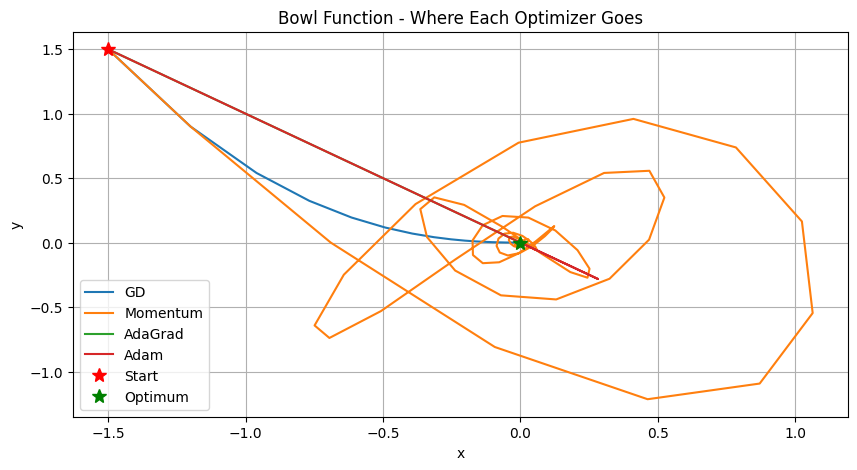

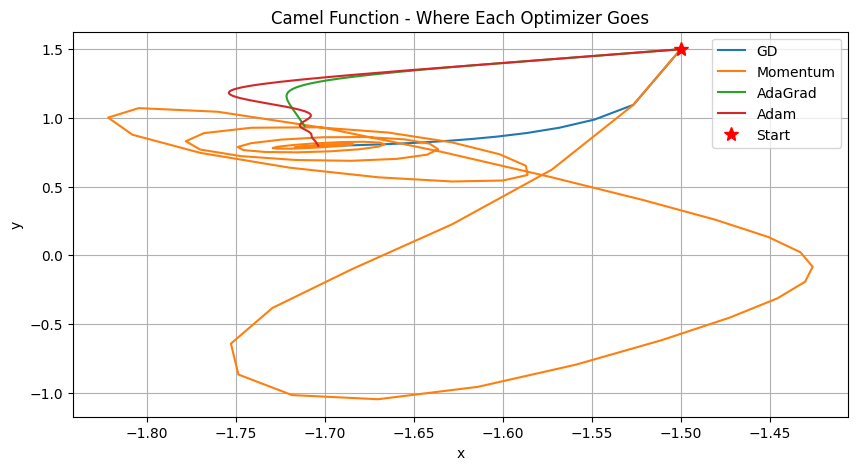

BOWL RESULTS:
  GD: loss = 0.000000e+00
  Momentum: loss = 0.000000e+00
  AdaGrad: loss = 1.334363e-26
  Adam: loss = 0.000000e+00

CAMEL RESULTS:
  GD: loss = -0.2155, position = (-1.70, 0.80)
  Momentum: loss = -0.2155, position = (-1.70, 0.80)
  AdaGrad: loss = 0.0592, position = (-1.71, 0.94)
  Adam: loss = -0.2155, position = (-1.70, 0.80)


In [29]:
# Plot 1: Loss vs Iteration for Bowl
plt.figure(figsize=(10, 5))
for name, (traj, losses) in results_bowl.items():
    plt.plot(losses, label=name)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Bowl Function - How Loss Decreases Over Time')
plt.legend()
plt.grid()
plt.show()

# Plot 2: Loss vs Iteration for Camel
plt.figure(figsize=(10, 5))
for name, (traj, losses) in results_camel.items():
    plt.plot(losses, label=name)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Camel Function - How Loss Decreases Over Time')
plt.legend()
plt.grid()
plt.show()

# Plot 3: Optimizer Paths in (x,y) for Bowl
plt.figure(figsize=(10, 5))
for name, (traj, _) in results_bowl.items():
    positions = traj.detach().numpy()
    plt.plot(positions[:, 0], positions[:, 1], label=name)
plt.plot(-1.5, 1.5, 'r*', markersize=10, label='Start')
plt.plot(0, 0, 'g*', markersize=10, label='Optimum')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Bowl Function - Where Each Optimizer Goes')
plt.legend()
plt.grid()
plt.show()

# Plot 4: Optimizer Paths in (x,y) for Camel
plt.figure(figsize=(10, 5))
for name, (traj, _) in results_camel.items():
    positions = traj.detach().numpy()
    plt.plot(positions[:, 0], positions[:, 1], label=name)
plt.plot(-1.5, 1.5, 'r*', markersize=10, label='Start')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Camel Function - Where Each Optimizer Goes')
plt.legend()
plt.grid()
plt.show()

# Print results
print("BOWL RESULTS:")
for name, (traj, losses) in results_bowl.items():
    print(f"  {name}: loss = {losses[-1]:.6e}")

print()
print("CAMEL RESULTS:")
for name, (traj, losses) in results_camel.items():
    final_pos = traj[-1].detach().numpy()
    print(f"  {name}: loss = {losses[-1]:.4f}, position = ({final_pos[0]:.2f}, {final_pos[1]:.2f})")

## Analysis

**Convex Bowl Function**

On the bowl function, all four optimizers successfully reach the minimum and achieve essentially zero loss. Gradient descent, momentum, AdaGrad, and Adam all converge to the global minimum at (0, 0). The bowl is a simple function with a single minimum, so all methods work well. The trajectories show they all take similar paths - going downhill directly to the center. Since the bowl is smooth and convex everywhere, there's no exploration needed, just straight descent toward the minimum.

**Six-Hump Camel Function**

The camel function is much harder. All four optimizers (GD, Momentum, and Adam) get stuck at the same local minimum with loss around -0.2155, located at position (-1.70, 0.80). This is not the global minimum (which is at -1.0316). AdaGrad is slightly different, reaching position (-1.71, 0.94) with loss 0.0592. None of them find the true global minimum despite running for 2000 iterations. This happens because once an optimizer reaches a local minimum where gradients are very small, it cannot escape - all directions appear to go uphill. The learning rates we chose are not sufficient to help them explore beyond this local minimum.

**What This Reveals**

The results show an important lesson: on simple problems like the bowl, all optimizers work equally well. On hard problems like the camel with multiple minima, the choice of optimizer matters less than having the right hyperparameters. All four methods got trapped in the same location because they use the same learning rate and starting point. To find better solutions on the camel, we would need to either increase iterations, decrease the learning rate, use a different starting point, or try different optimizer settings. The optimizer itself isn't the bottleneck - the hyperparameter tuning is.

### **Knowledge Bonus.** An attempt at explaining the L1 regularization phenomenon + a bit about proximal descent



The antigradient of the regularized loss $\mathcal{L}_{reg}(w) = \mathcal{L}(w) + \lambda\|w\|_1$ is
$$-\nabla_w\mathcal{L}_{reg}(w) = -\nabla_w\mathcal{L}(w) - \lambda\cdot \mathrm{sign}(w),$$
where $\mathrm{sgn}$ is the elementwise sign. This means that during the gradient descent the $i$-th coordinate of $w$ changes as
$$w_i \mapsto w_i - \alpha\frac{\partial}{\partial w_i}\mathcal{L}(w) + \begin{cases}
-\alpha\lambda,\mbox{ if $w_i > 0$},\\
+\alpha\lambda,\mbox{ if $w_i < 0$},
\end{cases},$$
where $\alpha$ is the step size. In other words, the rightmost summand pushes our $w_i$ towards $0$ with force $\alpha\lambda$. Now, imagine that the $i$-th feature is not very important. In this case, most likely, $\frac{\partial}{\partial w_i}\mathcal{L}(w)$ is small (change in $w_i$ doesn't change the loss much). So, the dominant force is the $\pm\alpha\lambda$, which may explain the almost-linear trajectories.

Of course, since $\alpha\lambda$ is constant and doesn't depend on $w_i$. This prevents us from converging to zero and explains the final noisy behaviour of $w_i$. We just leap around the origin.

I'd like to add here that if we used proximal descent, the step would become a two-step procedure like this:

$$w_i \mapsto w_i - \alpha\frac{\partial}{\partial w_i}\mathcal{L}(w),\\
w_i\mapsto\begin{cases}
w_i - \alpha\lambda,\mbox{ if $w_i \geqslant \alpha\lambda$},\\
0,\mbox{ if $|w_i| > \alpha\lambda$},\\
w_i + \alpha\lambda,\mbox{ if $w_i \leqslant -\alpha\lambda$},\\
\end{cases}$$
This way, small values of $w_i$ will be automatically zeroed, and they will only be able to escape zero again if the gradient push them hard enough.

**Comparison with L2 regularization**. For L2 regularization, the gradient step for the $i$-th coordinate would be
$$w_i \mapsto w_i - \alpha\frac{\partial}{\partial w_i}\mathcal{L}(w) - 2\alpha\lambda w_i$$
The rightmost term here depends on $w_i$; the closer it is to zero, the less influential it is, and the more important $\alpha\frac{\partial}{\partial w_i}\mathcal{L}(w)$ becomes. However, if the $i$-th feature is so worthless that $\alpha\frac{\partial}{\partial w_i}\mathcal{L}(w)\approx 0$, the process
$$w_i \mapsto w_i -  2\alpha\lambda w_i$$
converges to zero in contrast with the leaping behaviour of
$$w_i\mapsto w_i \pm\alpha\lambda$$